# Ramsey phase monitoring and correction with Qiskit 2
This notebook implements the first platform experiment in *ProjectDescription08*, Project 3. Aer runs a Ramsey sentinel and a separate target circuit. They share a simulated phase trajectory. At each selected monitoring time the controller sees sentinel counts, updates its posterior, and forecasts the target phase at the selected actuation time. Aer applies the forecast-based correction to the target before a separate verification measurement.

Use your `qiskit2` environment as the Jupyter kernel and select **Run All**. If dependencies are missing, run `%pip install "qiskit>=2,<3" "qiskit-aer>=0.17" numpy scipy pandas matplotlib` in that kernel, then restart it. No IBM credentials are needed.

## 1. Who sets what?

| Owner | Settings |
|---|---|
| Experiment designer (you) | Monitoring times, latency or explicit target times, sentinel and verification shot counts, and random seed. |
| Simulator (editable scenario inputs) | Drift dynamics and readout error rates that generate the data. |
| Controller (editable modeling assumptions) | Prior and transition model, assumed readout calibration, and posterior-loss rule. |
| Evaluator (you) | Acceptable absolute residual phase in radians. Set it before looking at the outcomes. |

The author supplied illustrative defaults. True and assumed dynamics initially match, a baseline for testing the feedback loop. Change the simulator inputs alone to test misspecification. Time is in integer ticks. Each tick is one AR(1) step, and both quadrature batches at a tick share the same phase. The default is one synthetic trajectory with multiple monitoring and correction decisions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import ndtr, xlogy, xlog1py
from qiskit import QuantumCircuit, __version__ as qiskit_version
from qiskit_aer import AerSimulator, __version__ as aer_version
from qiskit_aer.noise import NoiseModel, ReadoutError
from IPython.display import display

assert qiskit_version.split('.')[0] == '2', 'Select a Qiskit 2 kernel.'
print(f'Qiskit {qiskit_version} | Aer {aer_version}')

# Experiment designer
monitor_times = [0, 3, 6, 9, 12, 15, 18, 21, 24]
latency = 2
target_times = None  # Or give one integer tick per monitoring time.
monitor_shots = 512    # Per quadrature
verification_shots = 2048
seed = 62

# Simulator truth: (long-run mean, persistence, innovation SD), radians.
truth_model = (0.8, 0.94, 0.14)
truth_readout = (0.02, 0.04)  # P(report 1 | 0), P(report 0 | 1)

# Controller assumptions, set independently of simulator truth.
filter_model = (0.8, 0.94, 0.14)
assumed_readout = (0.02, 0.04)
grid_step = 0.02

# Evaluator
phase_tolerance = 0.25

if target_times is None:
    target_times = [t + latency for t in monitor_times]
assert len(monitor_times) == len(target_times) > 0
assert all(isinstance(t, int) and t >= 0 for t in monitor_times + target_times)
assert all(a < b for a, b in zip(monitor_times, monitor_times[1:]))
assert all(t <= u for t, u in zip(monitor_times, target_times))
assert monitor_shots > 0 and verification_shots > 0
assert 0 < phase_tolerance <= np.pi and grid_step > 0
for _, rho, sd in (truth_model, filter_model):
    assert abs(rho) < 1 and sd > 0
for e0, e1 in (truth_readout, assumed_readout):
    assert min(e0, e1) >= 0 and e0 + e1 < 1

Qiskit 2.5.2 | Aer 0.17.2


## 2. Generate the hidden phase and build the Ramsey circuits

The simulator uses a stationary Gaussian AR(1) for the unwrapped phase, with transition mean $mu+
ho(	heta_t-mu)$ and innovation SD $sigma$. Ramsey observations depend on that phase modulo $2pi$. The controller carries probability over the unwrapped grid so distinct branches can contribute to the forecast. We use unit sensitivity for this first experiment.

The circuit prepares $|+\rangle$, applies the latent $R_z(	heta)$, optionally applies the target correction $R_z(-a)$, and measures after an analysis rotation $R_z(-phi)$ and a Hadamard. Thus the ideal zero probability is $(1+cos(	heta-a-phi))/2$. Settings $phi=0,pi/2$ measure cosine and sine. Aer flips reported outcomes according to the simulator's readout rates.

In [2]:
seed_truth, seed_aer = np.random.SeedSequence(seed).spawn(2)
truth_rng = np.random.default_rng(seed_truth)
aer_rng = np.random.default_rng(seed_aer)
mu, rho, sigma = truth_model
phase = np.empty(max(target_times) + 1)
phase[0] = truth_rng.normal(mu, sigma / np.sqrt(1 - rho**2))
for t in range(1, len(phase)):
    phase[t] = mu + rho * (phase[t-1] - mu) + truth_rng.normal(0, sigma)

e0, e1 = truth_readout
noise = NoiseModel()
noise.add_all_qubit_readout_error(ReadoutError([[1-e0, e0], [e1, 1-e1]]))
aer = AerSimulator(noise_model=noise, max_parallel_threads=1)
quadratures = np.array([0., np.pi / 2])

def ramsey(theta, phi, correction=None):
    circuit = QuantumCircuit(1, 1)
    circuit.h(0)
    circuit.rz(theta, 0)
    if correction is not None:
        circuit.barrier()  # Keep the correction visible as a separate gate.
        circuit.rz(-correction, 0)
    circuit.rz(-phi, 0)
    circuit.h(0)
    circuit.measure(0, 0)
    return circuit

def read_zero_counts(circuits, shots):
    result = aer.run(circuits, shots=shots,
                     seed_simulator=int(aer_rng.integers(1, 2**31))).result()
    return np.array([result.get_counts(i).get('0', 0)
                     for i in range(len(circuits))])

print(ramsey(0.7, 0, correction=0.5).draw(output='text'))

     ┌───┐┌─────────┐ ░ ┌──────────┐┌───────┐┌───┐┌─┐
  q: ┤ H ├┤ Rz(0.7) ├─░─┤ Rz(-0.5) ├┤ Rz(0) ├┤ H ├┤M├
     └───┘└─────────┘ ░ └──────────┘└───────┘└───┘└╥┘
c: 1/══════════════════════════════════════════════╩═
                                                   0 


## 3. Update, forecast, and apply the correction

At monitoring tick $t$, propagate the previous posterior through any gap and update with two binomial likelihoods using the **assumed** readout calibration. For target tick $u$, propagate the updated distribution another $u-t$ steps. Under circular loss $1-cos(	heta_u-a)$, the optimal action is $a=arg E[e^{i	heta_u}midmathcal D_t]$. Its posterior expected advantage over no correction is $|m|-operatorname{Re}(m)$, where $m=E[e^{i	heta_u}midmathcal D_t]$. An essentially zero resultant produces a zero correction. The current-estimate baseline uses the same rule at $t$.

A grid transition assigns probability to bins by Gaussian CDF differences. The grid covers at least eight stationary standard deviations on either side of the controller's mean. For sensitivity checks, refine the grid and compare the resulting actions. The monitoring stream alone drives the controller. All target verification shots are held out.

In [3]:
mu_f, rho_f, sigma_f = filter_model
stationary_sd = sigma_f / np.sqrt(1 - rho_f**2)
half_width = max(2*np.pi, 8*stationary_sd)
grid = np.linspace(mu_f-half_width, mu_f+half_width,
                   int(np.ceil(2*half_width/grid_step))+1)
edges = np.r_[-np.inf, (grid[1:] + grid[:-1])/2, np.inf]
transition_mean = mu_f + rho_f*(grid - mu_f)
transition = np.diff(ndtr((edges[None, :] - transition_mean[:, None]) / sigma_f),
                     axis=1)
posterior = np.diff(ndtr((edges - mu_f)/stationary_sd))
unit_phase = np.exp(1j*grid)
e0_f, e1_f = assumed_readout
p_zero = e1_f + (1-e0_f-e1_f)*(1+np.cos(grid - quadratures[:, None]))/2

def predict(weights, steps):
    for _ in range(steps):
        weights = weights @ transition
    return weights

def update(weights, counts):
    log_likelihood = (xlogy(counts[:, None], p_zero)
                      + xlog1py((monitor_shots-counts)[:, None], -p_zero)).sum(axis=0)
    with np.errstate(divide='ignore'):
        log_weight = np.log(weights) + log_likelihood
    if not np.isfinite(log_weight.max()):
        raise ValueError('Observation has zero likelihood on the filter grid.')
    weight = np.exp(log_weight - log_weight.max())
    return weight / weight.sum()

def action(moment):
    return float(np.angle(moment)) if abs(moment) > 1e-12 else 0.0

ledger = []
previous_time = 0
for t, u in zip(monitor_times, target_times):
    counts = read_zero_counts([ramsey(phase[t], phi) for phi in quadratures],
                              monitor_shots)
    posterior = update(predict(posterior, t-previous_time), counts)
    future = predict(posterior, u-t)
    moment = future @ unit_phase
    ledger.append(dict(monitor=t, target=u, zero_X=counts[0], zero_Y=counts[1],
                       current=action(posterior @ unit_phase),
                       forecast=action(moment), concentration=abs(moment),
                       expected_gain=abs(moment)-moment.real))
    previous_time = t

ledger = pd.DataFrame(ledger)
display(ledger.round(3))

,monitor,target,zero_X,zero_Y,current,forecast,concentration,expected_gain
0,0,2,307,499,1.384,1.316,0.981,0.734
1,3,5,442,432,0.767,0.771,0.981,0.277
2,6,8,437,424,0.748,0.754,0.981,0.266
3,9,11,434,421,0.748,0.754,0.981,0.266
4,12,14,438,432,0.767,0.771,0.981,0.278
5,15,17,484,380,0.469,0.508,0.981,0.124
6,18,20,462,397,0.591,0.615,0.981,0.180
7,21,23,476,388,0.519,0.551,0.981,0.145
8,24,26,472,395,0.551,0.580,0.981,0.160


## 4. Did we fix the phase?

The evaluator knows the injected target phase. For each target tick, the signed residual is $r=arg e^{i(	heta_u-a)}$. **A target is within specification if $|r|leq$ the chosen tolerance.** The default 0.25 rad is about 14.3 degrees. Across the selected target ticks, compare the within-tolerance fraction and the mean circular loss $1-cos r$. A method can improve the loss and still miss the tolerance.

Aer independently verifies each action on the same target trajectory using X/Y Ramsey measurements. With calibrated readout, the X estimate measures $cos r$, so its average estimates alignment with the desired zero phase. The Y estimate checks the signed displacement. The table also reports $|operatorname{mean}(e^{ir})|$, which measures concentration and can be high even with a systematic offset. The X-alignment difference includes a shot-only standard error conditional on the selected trajectory. To quantify performance across drift realizations, repeat the full experiment over independent seeds.

Forecast correction met tolerance at 6/9 targets, versus 0/9 without correction.
Reduction in mean circular loss: +0.1748
Aer X alignment gain: +0.1689 (shot-only SE 0.0058)


,Within tolerance,Targets,Mean circular loss,Residual concentration,Aer mean X,Aer mean Y
Policy,,,,,,
No correction,0,9,0.2039,0.9934,0.7970,0.5962
Current estimate,6,9,0.0344,0.9690,0.9646,-0.0686
Forecast,6,9,0.0291,0.9751,0.9659,-0.0928


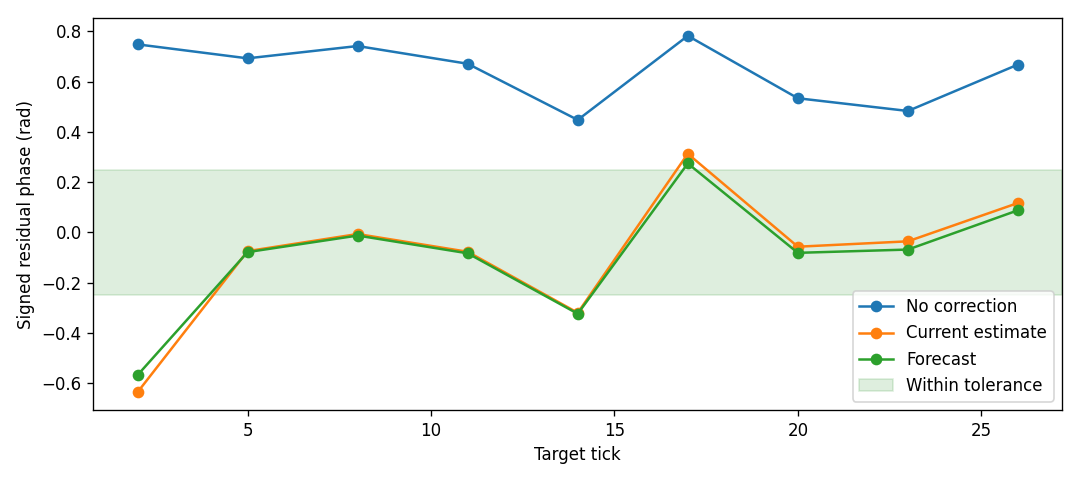

In [4]:
policies = {'No correction': np.zeros(len(ledger)),
            'Current estimate': ledger['current'].to_numpy(),
            'Forecast': ledger['forecast'].to_numpy()}
target_phase = phase[ledger['target'].to_numpy()]
rows, details, shot_variance = [], {}, {}
# Evaluator uses the readout calibration of the simulated verification circuit.
# This calibration is independent of the latent phase and can be estimated
# from separate prepared-zero and prepared-one experiments in a later study.
gain = 1-e0-e1
for name, angles in policies.items():
    circuits = [ramsey(theta, phi, None if name == 'No correction' else angle)
                for theta, angle in zip(target_phase, angles)
                for phi in quadratures]
    p = read_zero_counts(circuits, verification_shots).reshape(-1, 2) / verification_shots
    xy = 2*(p-e1)/gain - 1
    residual = np.angle(np.exp(1j*(target_phase-angles)))
    within = np.abs(residual) <= phase_tolerance
    details[name] = residual
    shot_variance[name] = np.sum(4*p[:, 0]*(1-p[:, 0]) /
                                 (verification_shots*gain**2))/len(p)**2
    rows.append({'Policy': name, 'Within tolerance': within.sum(),
                 'Targets': len(within), 'Mean circular loss': np.mean(1-np.cos(residual)),
                 'Residual concentration': abs(np.mean(np.exp(1j*residual))),
                 'Aer mean X': xy[:, 0].mean(), 'Aer mean Y': xy[:, 1].mean()})

summary = pd.DataFrame(rows).set_index('Policy')
display(summary.round(4))
base, forecast = summary.loc['No correction'], summary.loc['Forecast']
difference = forecast['Aer mean X'] - base['Aer mean X']
se = np.sqrt(shot_variance['Forecast'] + shot_variance['No correction'])
print(f"Forecast correction met tolerance at {int(forecast['Within tolerance'])}"
      f"/{len(ledger)} targets, versus {int(base['Within tolerance'])}/{len(ledger)} without correction.")
print(f"Reduction in mean circular loss: {base['Mean circular loss'] - forecast['Mean circular loss']:+.4f}")
print(f"Aer X alignment gain: {difference:+.4f} (shot-only SE {se:.4f})")

fig, ax = plt.subplots(figsize=(9, 4))
for name, residual in details.items():
    ax.plot(ledger['target'], residual, 'o-', label=name)
ax.axhspan(-phase_tolerance, phase_tolerance, alpha=0.13, color='green',
           label='Within tolerance')
ax.set(xlabel='Target tick', ylabel='Signed residual phase (rad)')
ax.legend()
fig.tight_layout()
plt.show()

## 5. Try a different measurement schedule

Set latency to zero and rerun. The two correction policies should issue identical angles, with verification estimates differing by shot noise. Then increase latency, widen the gaps between monitoring times, or change the true persistence while keeping the assumed persistence fixed. Watch the target tolerance counts, circular loss, and the Aer alignment gain. The assumed dynamics can be useful when a forecast shrinks a stale estimate toward the long-run mean, and that benefit depends on the accuracy of the model and how long the controller must wait.